# Group C: Muscle fatigue during effort and rest
Authors: Ayesha Waheed, Albatoul Ahmad, Shunan Yin, Date: November 2026

# 1. Understanding the model

This model describes how fatigue and recovery capacity change during exercise. It has two variables:
- F is the normalized fatigue level. F = 0 means no modeled fatigue; F = 1 means the highest level represented by the model.
- R is the normalized recovery capacity. R = 1 means full capacity; smaller values mean less recovery capacity.
The model equations are:
$$
\frac{dF}{dt} = \alpha P(1-F) - \beta FR
$$
$$
\frac{dR}{dt} = \gamma(1-R) - \delta FR - \varepsilon PR
$$
The symbols dF/dt and dR/dt describe how quickly F and R change over time. A positive value means that variable is increasing. A negative value means it is decreasing.

In the first equation, αP(1-F) increases fatigue during exercise. Higher effort P makes this effect stronger, while (1-F) means fatigue builds more slowly as F approaches 1. The term βFR reduces fatigue. Its effect depends on both the fatigue level and the recovery capacity.

In the second equation, γ(1-R) restores recovery capacity toward 1. The terms δFR and εPR reduce recovery capacity. The first depends on fatigue and recovery capacity; the second depends on effort and recovery capacity.

Time is measured in minutes. The parameter values are α = 0.60, β = 0.80, γ = 0.30, δ = 0.25, and ε = 0.15 per minute. The effort P is held constant during each simulation.

These variables are normalized quantities in a simplified model. They are not direct measurements of muscle force, recovery time, or power.

# 2. Equilibria and stability (P = 1)

The model describes fatigue $F$ and recovery capacity $R$ during sustained effort $P$:

$$\dot F = \alpha P (1-F) - \beta F R, \qquad \dot R = \gamma (1-R) - \delta F R - \varepsilon P R$$

**Goal of this section**
1. Plot the two nullclines on $[0,1]^2$ for $P=1$.
2. Find the equilibrium at their intersection.
3. Draw a few arrows near it to see whether it is attracting or repelling.
4. Explain briefly.

## 2.1. Parameters and the model

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

alpha, beta, gamma, delta, eps = 0.60, 0.80, 0.30, 0.25, 0.15
P = 1.0   # effort intensity (change to 1.6 for Section 4)

def f(F, R):
    # dF/dt: fatigue builds up with effort, recovery capacity removes it
    return alpha*P*(1 - F) - beta*F*R

def g(F, R):
    # dR/dt: recovery regenerates toward 1, fatigue and effort consume it
    return gamma*(1 - R) - delta*F*R - eps*P*R

## 2.2. Nullclines

A **nullcline** is the curve where one variable has zero rate of change.

- **F-nullcline** ($\dot F = 0$): $\alpha P(1-F) = \beta F R$, so
  $$F = \frac{\alpha P}{\alpha P + \beta R}$$
- **R-nullcline** ($\dot R = 0$): $\gamma(1-R) = \delta F R + \varepsilon P R$, so
  $$R = \frac{\gamma}{\gamma + \delta F + \varepsilon P}$$

Where they cross, **both** rates are zero, which is an **equilibrium**: fatigue and recovery are in balance.

In [3]:
def F_null(R):
    return alpha*P / (alpha*P + beta*R)

def R_null(F):
    return gamma / (gamma + delta*F + eps*P)

## 2.3. Finding the equilibrium

Substituting $R = R_{null}(F)$ into the F-nullcline gives one equation in $F$ only. We solve it numerically with a root finder (`brentq`) on $[0,1]$, then get $R^*$ from the R-nullcline.

In [4]:
h = lambda F: F - F_null(R_null(F))
Fstar = brentq(h, 0, 1)
Rstar = R_null(Fstar)

print(f"Equilibrium for P = {P}:  F* = {Fstar:.4f},  R* = {Rstar:.4f}")
print("Check: f(F*,R*) =", f(Fstar, Rstar), "  g(F*,R*) =", g(Fstar, Rstar))

Equilibrium for P = 1.0:  F* = 0.6000,  R* = 0.5000
Check: f(F*,R*) = 2.7755575615628914e-15   g(F*,R*) = 0.0


**Hand check (P = 1):** $R^* = \dfrac{0.3}{0.45+0.25\cdot 0.6} = 0.5$ and $F^* = \dfrac{0.6}{0.6+0.8\cdot 0.5} = 0.6$.

So at constant effort $P=1$, fatigue settles at 60 % and 50 % of the recovery capacity remains.

## 2.4. Plot: nullclines, equilibrium and direction arrows

The arrows are computed from the model itself: at each point we evaluate $(\dot F, \dot R)$ and draw a short arrow of fixed length in that direction.
If they all point toward the intersection, the equilibrium is **attracting**.

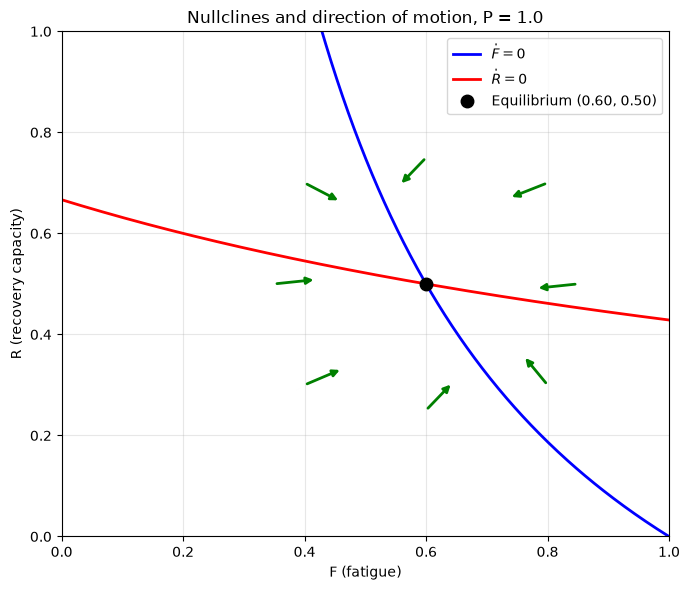

In [5]:
Fgrid = np.linspace(0, 1, 400)
Rgrid = np.linspace(0, 1, 400)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(F_null(Rgrid), Rgrid, 'b-', lw=2, label=r"$\dot F=0$")
ax.plot(Fgrid, R_null(Fgrid), 'r-', lw=2, label=r"$\dot R=0$")
ax.plot(Fstar, Rstar, 'ko', ms=9, label=f"Equilibrium ({Fstar:.2f}, {Rstar:.2f})")

offsets = [(-0.2,-0.2),(0.2,-0.2),(-0.2,0.2),(0.2,0.2),
           (0,-0.25),(0,0.25),(-0.25,0),(0.25,0)]
for dF, dR in offsets:
    x, y = Fstar + dF, Rstar + dR
    if 0 <= x <= 1 and 0 <= y <= 1:
        u, v = f(x, y), g(x, y)
        n = np.hypot(u, v)
        ax.annotate("", xy=(x + 0.07*u/n, y + 0.07*v/n), xytext=(x, y),
                    arrowprops=dict(arrowstyle="-|>", color="green", lw=2))

ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("F (fatigue)"); ax.set_ylabel("R (recovery capacity)")
ax.set_title(f"Nullclines and direction of motion, P = {P}")
ax.legend(loc="upper right"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2.5. Reading the figure

- **Left/right of the blue curve:** if $F$ is below its nullcline, $\dot F>0$ (fatigue grows); above it, $\dot F<0$ (fatigue falls).
- **Below/above the red curve:** if $R$ is below its nullcline, $\dot R>0$ (recovery regenerates); above it, $\dot R<0$ (recovery is consumed).
- In all four regions around the crossing, the arrows point **back toward** the intersection.

**Conclusion:** the equilibrium $(F^*,R^*)\approx(0.6,\,0.5)$ is **attracting** (a stable node). The nullclines cross only once, so there is no other steady state in $[0,1]^2$.

# 3. Numerical simulation for P = 1

## Aim

We use Python to simulate how fatigue, F, and recovery capacity, R, change over 40 minutes when the effort stays at P = 1. We compare two starting states: (F, R) = (0.1, 0.9) and (F, R) = (0.8, 0.2).

## Method: explicit Euler

The model equations give the current rates of change, dF/dt and dR/dt. Explicit Euler uses those rates to estimate the values a short time later:

- New F = current F + h × current rate of F
- New R = current R + h × current rate of R

Here, h = 0.02 minutes, or 1.2 seconds. The code repeats this update 2,000 times to cover 40 minutes. At each step, it calculates both rates from the current values of F and R.

## What the code does

The function `simulate` runs the model from one starting state and stores the values over time. The loop then runs it once for each of the two starting states. The plot shows fatigue with solid lines and recovery capacity with dashed lines.

In [6]:
# Question 3 settings
h = 0.02          # Time step in minutes
end_time = 40.0   # Total simulation time in minutes
num_steps = int(end_time / h)
time = np.arange(num_steps + 1) * h

# Initial states required by the assignment
initial_conditions = [
    (0.1, 0.9),
    (0.8, 0.2),
]

def simulate(initial_F, initial_R):
    """Simulate F and R using explicit Euler."""
    F = np.zeros(num_steps + 1)
    R = np.zeros(num_steps + 1)

    F[0] = initial_F
    R[0] = initial_R

    for n in range(num_steps):
        # f and g calculate the current rates using the model equations
        F[n + 1] = F[n] + h * f(F[n], R[n])
        R[n + 1] = R[n] + h * g(F[n], R[n])

    return F, R

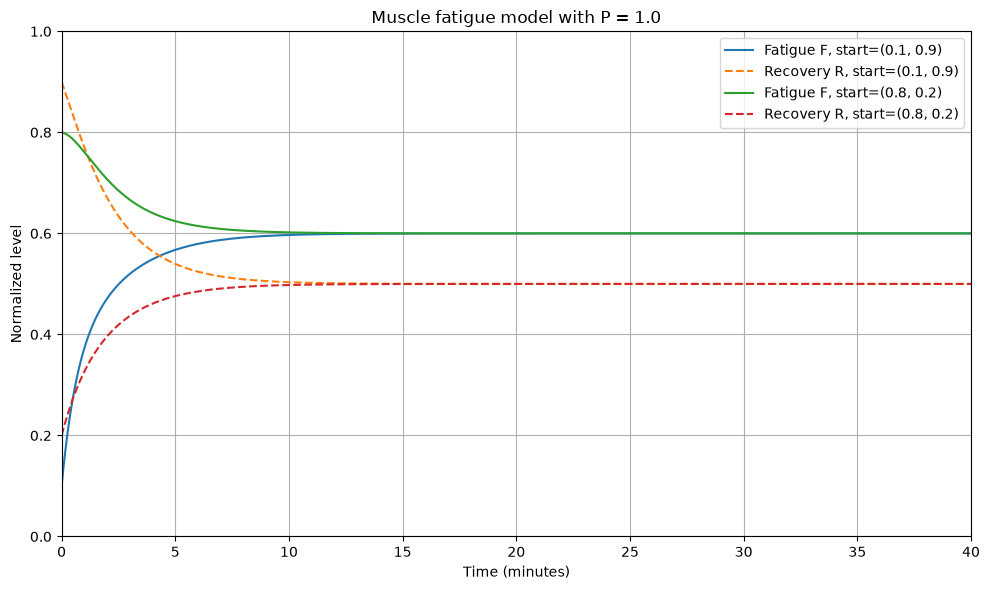

In [7]:
plt.figure(figsize=(10, 6))

for initial_F, initial_R in initial_conditions:
    F, R = simulate(initial_F, initial_R)
    start = f"start=({initial_F}, {initial_R})"

    # Solid lines show fatigue; dashed lines show recovery capacity
    plt.plot(time, F, label=f"Fatigue F, {start}")
    plt.plot(time, R, "--", label=f"Recovery R, {start}")

plt.xlabel("Time (minutes)")
plt.ylabel("Normalized level")
plt.title(f"Muscle fatigue model with P = {P}")
plt.xlim(0, end_time)
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## Results and interpretation

Compare how the two starting states change over time. In the plot, fatigue starts at 0.1 in the first simulation and 0.8 in the second. Recovery capacity starts at 0.9 and 0.2, respectively.

Both simulations approach approximately F = 0.60 and R = 0.50. This agrees with the equilibrium found in Question 2 for P = 1. The different curves show how the system moves from different starting states; their shared long-term levels suggest that both approach the same equilibrium.

The curves become flatter near the end because the rates of change get closer to zero. This is the behavior expected near an equilibrium. These are results from the model and the chosen starting states, not predictions for a specific athlete.